In [ ]:
# Music Recommendation and Song Popularity Analysis Using Machine Learning

## 1. Project Overview

This project aims to analyze Spotify music data and develop a machine learning system for predicting song popularity and recommending similar songs based on their audio features.

## 2. Project Objectives

- Analyze Spotify song characteristics using Exploratory Data Analysis (EDA).
- Predict song popularity using regression models.
- Recommend similar songs using content-based filtering and cosine similarity.
- Compare different machine learning models and evaluate their performance.

## 3. Dataset

- **Source:** Kaggle – Spotify Tracks Dataset
- **Dataset size:** 114,000 rows and 21 columns
- **Prediction target:** Popularity
- **ML task:** Regression

## 4. End Users

Music streaming platforms, music analysts, and listeners who want to discover songs based on their preferences.

## 5. Evaluation Metrics

MAE, RMSE, and R² score will be used to evaluate the regression models.

In [1]:
# libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_csv("dataset.csv")

In [4]:
data.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [6]:
data.shape

(114000, 21)

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [8]:
data.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [9]:
print("Total duplicate rows:", data.duplicated().sum())

print("Duplicate track IDs:", data['track_id'].duplicated().sum())

Total duplicate rows: 0
Duplicate track IDs: 24259


In [10]:
data[data['track_id'].duplicated(keep=False)].sort_values('track_id').head(20)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,...,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


In [11]:
data['track_id'].nunique()

89741

In [12]:
data.groupby('track_id')['track_genre'].nunique().value_counts().sort_index()

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

In [14]:
data[data['track_id'].duplicated(keep=False)].sort_values('track_id').head(20)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,...,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,...,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,...,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,...,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,...,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


In [15]:
print("Unique track IDs:", data['track_id'].nunique())

Unique track IDs: 89741


In [16]:
duplicate_tracks = data[data['track_id'].duplicated(keep=False)].sort_values('track_id')
duplicate_tracks[['track_id', 'track_name', 'artists','popularity', 'track_genre']].head(20)

,track_id,track_name,artists,popularity,track_genre
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,0,chill
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,0,soul
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,38,punk-rock
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,38,ska
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,rock
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,alternative
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,86,alt-rock
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,58,emo
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,58,sad
97533,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,47,sertanejo


In [17]:
duplicate_tracks.groupby('track_id')['popularity'].nunique().value_counts()

popularity
1    15921
2      720
Name: count, dtype: int64

In [18]:
varying_popularity_ids = (duplicate_tracks.groupby('track_id')['popularity'].nunique())

varying_popularity_ids = varying_popularity_ids[varying_popularity_ids > 1].index

data[data['track_id'].isin(varying_popularity_ids)][['track_id', 'track_name', 'artists','popularity', 'track_genre']].sort_values('track_id').head(20)

,track_id,track_name,artists,popularity,track_genre
102269,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,46,songwriter
57529,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,indie
99268,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,46,singer-songwriter
65813,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,k-pop
55776,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,indian
56324,00YwP3wJWiG8IxAA7OS9lo,Amake Amar Moto Thakte Dao,Anupam Roy,47,indie-pop
91138,014SIjoLDG1Ku19c5FlDYh,I Put A Spell On You,Creedence Clearwater Revival,3,rock
19042,014SIjoLDG1Ku19c5FlDYh,I Put A Spell On You,Creedence Clearwater Revival,0,country
89770,02jLfqc9gMo8PkHEGHY3OT,Si Te La Encuentras Por Ahí,Feid,82,reggaeton
88912,02jLfqc9gMo8PkHEGHY3OT,Si Te La Encuentras Por Ahí,Feid,82,reggae


In [19]:
data['Unnamed: 0'].head(10)

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64

In [20]:
data['Unnamed: 0'].nunique()

114000

In [21]:
data.drop(columns=['Unnamed: 0'], inplace=True)

In [22]:
data.shape

(114000, 20)

In [23]:
data[data.isnull().any(axis=1)]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [24]:
#duration values
print("Zero duration records:",(data['duration_ms'] == 0).sum())

print("Negative duration records:",(data['duration_ms'] < 0).sum())

Zero duration records: 1
Negative duration records: 0


In [26]:
print("Zero tempo records:",(data['tempo'] == 0).sum())

Zero tempo records: 157


In [27]:
zero_tempo = data[data['tempo'] == 0]

zero_tempo.head(10)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
4131,59gg6zQhSKGVnkT3hWAY3l,Max Richter;Lang Lang,Voyager - Essential Max Richter,The Departure,64,151506,False,0.0,0.03620,0,-22.519,0,0.0,0.994,0.940000,0.0958,0.0,0.0,0,ambient
4379,4acmzQsAeMJa5sGFSog7fu,Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,Jane Eyre - Original Motion Picture Soundtrack,The End of Childhood (feat. Jack Liebeck),55,73266,False,0.0,0.04450,0,-26.440,0,0.0,0.972,0.972000,0.0873,0.0,0.0,0,ambient
4664,1Kb2DqjHRvOcT5xeWtz3t5,Sylvain Chauveau,Des Plumes Dans La Tête,Ferme Les Yeux,53,68493,False,0.0,0.03230,2,-23.636,0,0.0,0.994,0.973000,0.0922,0.0,0.0,0,ambient
45670,6B9Mgf9smWqxDjA35VD6MK,Little Symphony,Rialto Beach,Campomoro,22,148711,False,0.0,0.00108,0,-30.204,1,0.0,0.952,0.991000,0.2420,0.0,0.0,0,guitar
45720,7i5OoyPXtSrqz9jobJfG1F,Little Symphony,Rialto Beach,Ritornello,23,102000,False,0.0,0.00129,7,-29.445,1,0.0,0.969,0.956000,0.1230,0.0,0.0,0,guitar
45729,0pTAEdockvKVSq1hhFqk7O,Little Symphony,Rialto Beach,Amager,22,133624,False,0.0,0.00400,0,-28.326,1,0.0,0.970,0.959000,0.1090,0.0,0.0,0,guitar
45773,1keWmyG6qyBbMagPBdgUKr,Little Symphony,Rialto Beach,Ionian,22,93125,False,0.0,0.02680,7,-30.100,1,0.0,0.964,0.993000,0.1240,0.0,0.0,0,guitar
59221,5BcyxCXrXuw4vsAqAiObWM,Leila Bela,Angra Manyu,Yes! No! I Mean Yes! No I Don't!,0,38333,False,0.0,0.57200,8,-16.286,1,0.0,0.872,0.000175,0.1190,0.0,0.0,0,iranian
59310,6hsyfegVY5yklJneM40mWi,Leila Bela,Angra Manyu,The Exorsism Begins...,0,8586,False,0.0,0.04000,8,-29.714,0,0.0,0.928,0.956000,0.1150,0.0,0.0,0,iranian
59473,48Nt8u7kYSTwE6axtE9hJO,Leila Bela,Angra Manyu,Leaving Her Quantum Journey Behind...,0,50186,False,0.0,0.03140,5,-28.194,0,0.0,0.723,0.000067,0.1290,0.0,0.0,0,iranian


In [28]:
zero_tempo[['track_name', 'artists', 'duration_ms','popularity', 'tempo', 'time_signature']]

,track_name,artists,duration_ms,popularity,tempo,time_signature
4131,The Departure,Max Richter;Lang Lang,151506,64,0.0,0
4379,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,73266,55,0.0,0
4664,Ferme Les Yeux,Sylvain Chauveau,68493,53,0.0,0
45670,Campomoro,Little Symphony,148711,22,0.0,0
45720,Ritornello,Little Symphony,102000,23,0.0,0
...,...,...,...,...,...,...
101988,Tin White Noise,Granular,182050,32,0.0,0
101993,Rain: Natural Recording,Rain Sounds,84219,32,0.0,0
113428,Aire de verano,El Ruido Blanco;Soñoliento Juan;Mantra para Do...,128000,27,0.0,0
113688,Ruido Rosa Puro - Una Hora Versión,El Ruido Blanco,3601693,24,0.0,0


In [29]:
print("Zero tempo and zero duration:",((data['tempo'] == 0) & (data['duration_ms'] == 0)).sum())

print("Zero tempo and zero time signature:",((data['tempo'] == 0) & (data['time_signature'] == 0)).sum())

Zero tempo and zero duration: 0
Zero tempo and zero time signature: 157


In [30]:
zero_tempo = data[data['tempo'] == 0]

zero_tempo.isnull().sum()

track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [31]:
zero_tempo[['danceability', 'energy', 'loudness',
            'speechiness', 'acousticness',
            'instrumentalness', 'liveness',
            'valence', 'tempo', 'time_signature']].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,157.0,157.000000,157.000000,157.0,157.000000,157.000000,157.000000,157.0,157.0,157.0
mean,0.0,0.122914,-22.092503,0.0,0.496735,0.650488,0.454720,0.0,0.0,0.0
std,0.0,0.250220,9.677911,0.0,0.408839,0.386391,0.320175,0.0,0.0,0.0
min,0.0,0.000000,-49.531000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
25%,0.0,0.000020,-27.035000,0.0,0.122000,0.289000,0.117000,0.0,0.0,0.0
50%,0.0,0.000638,-20.356000,0.0,0.360000,0.864000,0.389000,0.0,0.0,0.0
75%,0.0,0.062800,-16.680000,0.0,0.936000,0.984000,0.718000,0.0,0.0,0.0
max,0.0,0.999000,-0.689000,0.0,0.996000,1.000000,0.989000,0.0,0.0,0.0


In [32]:
zero_counts = (data == 0).sum(numeric_only=True)

print(zero_counts)

track_id                 0
artists                  0
album_name               0
track_name               0
popularity           16020
duration_ms              1
explicit            104253
danceability           157
energy                   1
key                  13061
loudness                 0
mode                 41319
speechiness            157
acousticness            39
instrumentalness     38763
liveness                 2
valence                176
tempo                  157
time_signature         163
track_genre              0
dtype: int64


In [33]:
print("Zero danceability:",(data['danceability'] == 0).sum())

print("Zero speechiness:",(data['speechiness'] == 0).sum())

print("Zero energy:",(data['energy'] == 0).sum())

Zero danceability: 157
Zero speechiness: 157
Zero energy: 1


In [36]:
data[(data['duration_ms'] == 0) |(data['energy'] == 0) |(data['liveness'] == 0)][['track_id', 'track_name', 'artists','popularity', 'duration_ms','energy', 'liveness']]

,track_id,track_name,artists,popularity,duration_ms,energy,liveness
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,0,0,0.583000,0.0747
101577,3gIEb1mxGFTMlJAkaYaG2Q,Pure White Noise - Loopable with No Fade,Sleep Baby Sleep;Relaxation;White Noise Medita...,35,73886,0.000000,0.0000
101797,1U4qWTytgM8NPfJzax6Gqh,"White Noise - Loopable, No Fade",White Noise Sleep Sounds;Static White Noise So...,33,142305,0.000019,0.0000


In [37]:
data[data['duration_ms'] <= 0][
    ['track_id', 'track_name', 'artists',
     'duration_ms', 'popularity']
]

,track_id,track_name,artists,duration_ms,popularity
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,0,0


In [38]:
data = data[data['duration_ms'] > 0].copy()

In [39]:
print("Updated shape:", data.shape)
print("Missing values:\n", data.isnull().sum())

Updated shape: (113999, 20)
Missing values:
 track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [41]:
invalid_audio = data[
    (data['danceability'] == 0) &
    (data['speechiness'] == 0) &
    (data['tempo'] == 0) &
    (data['time_signature'] == 0)
]

print("Records with all four zero values:", len(invalid_audio))

Records with all four zero values: 157


In [42]:
data.loc[
    (data['danceability'] == 0) &
    (data['speechiness'] == 0) &
    (data['tempo'] == 0) &
    (data['time_signature'] == 0),
    ['danceability', 'speechiness', 'tempo', 'time_signature']
] = np.nan

In [43]:
data.isnull().sum()

track_id              0
artists               0
album_name            0
track_name            0
popularity            0
duration_ms           0
explicit              0
danceability        157
energy                0
key                   0
loudness              0
mode                  0
speechiness         157
acousticness          0
instrumentalness      0
liveness              0
valence               0
tempo               157
time_signature      157
track_genre           0
dtype: int64

In [44]:
data.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,113999.000000,1.139990e+05,113842.000000,113999.000000,113999.000000,113999.000000,113999.000000,113842.000000,113999.000000,113999.000000,113999.000000,113999.000000,113842.000000,113842.000000
mean,33.238827,2.280312e+05,0.567582,0.641383,5.309126,-8.258950,0.637558,0.084769,0.314907,0.156051,0.213554,0.474066,122.316149,3.909418
std,22.304959,1.072961e+05,0.172380,0.251530,3.559999,5.029357,0.480708,0.105759,0.332522,0.309556,0.190378,0.259261,29.653539,0.407887
min,0.000000,8.586000e+03,0.051300,0.000000,0.000000,-49.531000,0.000000,0.022100,0.000000,0.000000,0.000000,0.000000,30.200000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.429500,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.049000,0.169000,0.000042,0.132000,0.464000,122.023000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084600,0.597500,0.049000,0.273000,0.683000,140.077750,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [45]:
audio_features = [
    'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness',
    'instrumentalness', 'liveness',
    'valence', 'tempo', 'duration_ms'
]

data[audio_features].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,113842.000000,113999.000000,113999.000000,113842.000000,113999.000000,113999.000000,113999.000000,113999.000000,113842.000000,1.139990e+05
mean,0.567582,0.641383,-8.258950,0.084769,0.314907,0.156051,0.213554,0.474066,122.316149,2.280312e+05
std,0.172380,0.251530,5.029357,0.105759,0.332522,0.309556,0.190378,0.259261,29.653539,1.072961e+05
min,0.051300,0.000000,-49.531000,0.022100,0.000000,0.000000,0.000000,0.000000,30.200000,8.586000e+03
25%,0.456000,0.472000,-10.013000,0.035900,0.016900,0.000000,0.098000,0.260000,99.429500,1.740660e+05
50%,0.580000,0.685000,-7.004000,0.049000,0.169000,0.000042,0.132000,0.464000,122.023000,2.129060e+05
75%,0.695000,0.854000,-5.003000,0.084600,0.597500,0.049000,0.273000,0.683000,140.077750,2.615060e+05
max,0.985000,1.000000,4.532000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.237295e+06


In [46]:
audio_features = [
    'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness',
    'instrumentalness', 'liveness',
    'valence', 'tempo', 'duration_ms'
]

data[audio_features].describe().T

,count,mean,std,min,25%,50%,75%,max
danceability,113842.0,0.567582,0.172380,0.0513,0.4560,0.580000,0.69500,0.985
energy,113999.0,0.641383,0.251530,0.0000,0.4720,0.685000,0.85400,1.000
loudness,113999.0,-8.258950,5.029357,-49.5310,-10.0130,-7.004000,-5.00300,4.532
speechiness,113842.0,0.084769,0.105759,0.0221,0.0359,0.049000,0.08460,0.965
acousticness,113999.0,0.314907,0.332522,0.0000,0.0169,0.169000,0.59750,0.996
instrumentalness,113999.0,0.156051,0.309556,0.0000,0.0000,0.000042,0.04900,1.000
liveness,113999.0,0.213554,0.190378,0.0000,0.0980,0.132000,0.27300,1.000
valence,113999.0,0.474066,0.259261,0.0000,0.2600,0.464000,0.68300,0.995
tempo,113842.0,122.316149,29.653539,30.2000,99.4295,122.023000,140.07775,243.372
duration_ms,113999.0,228031.153387,107296.057716,8586.0000,174066.0000,212906.000000,261506.00000,5237295.000


In [48]:
data.nlargest(10, 'duration_ms')[['track_name', 'artists', 'duration_ms', 'popularity']]

,track_name,artists,duration_ms,popularity
73617,Unity (Voyage Mix) Pt. 1,Tale Of Us,5237295,35
10935,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,11
10984,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,11
24348,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,4730302,8
73840,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,4563897,17
13344,House of Om - Mark Farina - Continuous Mix,Mark Farina,4447520,11
13245,Live In Tokyo - Continuous Mix,Mark Farina,4339826,11
13195,Greenhouse Construction,Mark Farina,4334721,12
27926,"NQ State of Mind, Vol. 1 - Continuous DJ Mix",Lenzman;Dan Stezo,4246206,15
101390,Ocean Waves Sounds,Ocean Sounds,4120258,39


In [50]:
data.nlargest(10, 'loudness')[['track_name', 'artists', 'loudness', 'popularity']]

,track_name,artists,loudness,popularity
17574,Fate Dance,Five Star Hotel,4.532,16
59225,Islamic Capitalism,Najand,3.156,0
38840,Time Bomb,The Red Pears,2.574,25
59337,A Better World Is Possible,Najand,1.864,0
37738,TIPO HARIEL - SEI QUE E RARIDADE -,DJ BRUNO PRADO,1.821,44
17895,Malfunction,Free Refills,1.795,15
59833,Preaching for the Deaf,Najand,1.700,0
37548,AUTOMOTIVO DAS PIRANHA - VEM COMER MINHA TCHEC...,DJ Arana,1.682,47
17788,The Mall,Free Refills,1.673,16
69699,"Mel Nattu Isai (From ""Jodi"")",Sujatha,1.416,22


In [51]:
data[data['loudness'] > 0][['track_name', 'artists', 'loudness', 'popularity']]

,track_name,artists,loudness,popularity
5307,それは小さな光のような,Sayuri,0.698,36
5710,それは小さな光のような,Sayuri,0.698,52
10033,Stigma - Burr Oak Remix,Noisia;Burr Oak,0.025,32
10137,Ganja - Deekline & Kleu Remix,Dub Pistols;Deekline;Kleu,0.082,19
10705,STARS,DJ Fixx,0.202,12
...,...,...,...,...
83904,Love U,Marshmello,0.605,41
87512,El Terrón,"Sergio Vega ""El Shaka""",0.681,45
109692,Beat the system,Nosferatu,0.550,27
109870,Everytime We Touch - Fallen Superhero Remix,Cascada;Fallen Superhero,0.006,53


In [52]:
print("Positive loudness records:",(data['loudness'] > 0).sum())

Positive loudness records: 90


### IQR METHOD

In [53]:
Q1 = data['duration_ms'].quantile(0.25)
Q3 = data['duration_ms'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower)
print("Upper boundary:", upper)

outliers = data[
    (data['duration_ms'] < lower) |
    (data['duration_ms'] > upper)
]

print("Number of duration outliers:", len(outliers))

Q1: 174066.0
Q3: 261506.0
IQR: 87440.0
Lower boundary: 42906.0
Upper boundary: 392666.0
Number of duration outliers: 5616


In [54]:
positive_loudness = data[data['loudness'] > 0]

positive_loudness[['track_name', 'artists', 'loudness', 'popularity']].sort_values('loudness', ascending=False)

,track_name,artists,loudness,popularity
17574,Fate Dance,Five Star Hotel,4.532,16
59225,Islamic Capitalism,Najand,3.156,0
38840,Time Bomb,The Red Pears,2.574,25
59337,A Better World Is Possible,Najand,1.864,0
37738,TIPO HARIEL - SEI QUE E RARIDADE -,DJ BRUNO PRADO,1.821,44
...,...,...,...,...
10033,Stigma - Burr Oak Remix,Noisia;Burr Oak,0.025,32
27074,Stigma - Burr Oak Remix,Noisia;Burr Oak,0.025,32
27206,Pantheon - Evilnoiz Remix,Dirtyphonics;Ecraze;Evilnoiz,0.006,36
29866,Pantheon - Evilnoiz Remix,Dirtyphonics;Ecraze;Evilnoiz,0.006,36


In [55]:
positive_loudness['loudness'].describe()

count    90.000000
mean      0.685322
std       0.711490
min       0.006000
25%       0.175250
50%       0.550000
75%       0.918750
max       4.532000
Name: loudness, dtype: float64

In [56]:
positive_loudness.nlargest(20, 'loudness')[['track_name', 'artists', 'loudness', 'popularity']]

,track_name,artists,loudness,popularity
17574,Fate Dance,Five Star Hotel,4.532,16
59225,Islamic Capitalism,Najand,3.156,0
38840,Time Bomb,The Red Pears,2.574,25
59337,A Better World Is Possible,Najand,1.864,0
37738,TIPO HARIEL - SEI QUE E RARIDADE -,DJ BRUNO PRADO,1.821,44
17895,Malfunction,Free Refills,1.795,15
59833,Preaching for the Deaf,Najand,1.700,0
37548,AUTOMOTIVO DAS PIRANHA - VEM COMER MINHA TCHEC...,DJ Arana,1.682,47
17788,The Mall,Free Refills,1.673,16
69699,"Mel Nattu Isai (From ""Jodi"")",Sujatha,1.416,22


In [57]:
numerical_features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'duration_ms'
]

for column in numerical_features:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (data[column] < lower) |
        (data[column] > upper)
    ).sum()

    print(column, ":", outlier_count)

danceability : 463
energy : 0
loudness : 6173
speechiness : 13211
acousticness : 0
instrumentalness : 25246
liveness : 8642
valence : 0
tempo : 470
duration_ms : 5616


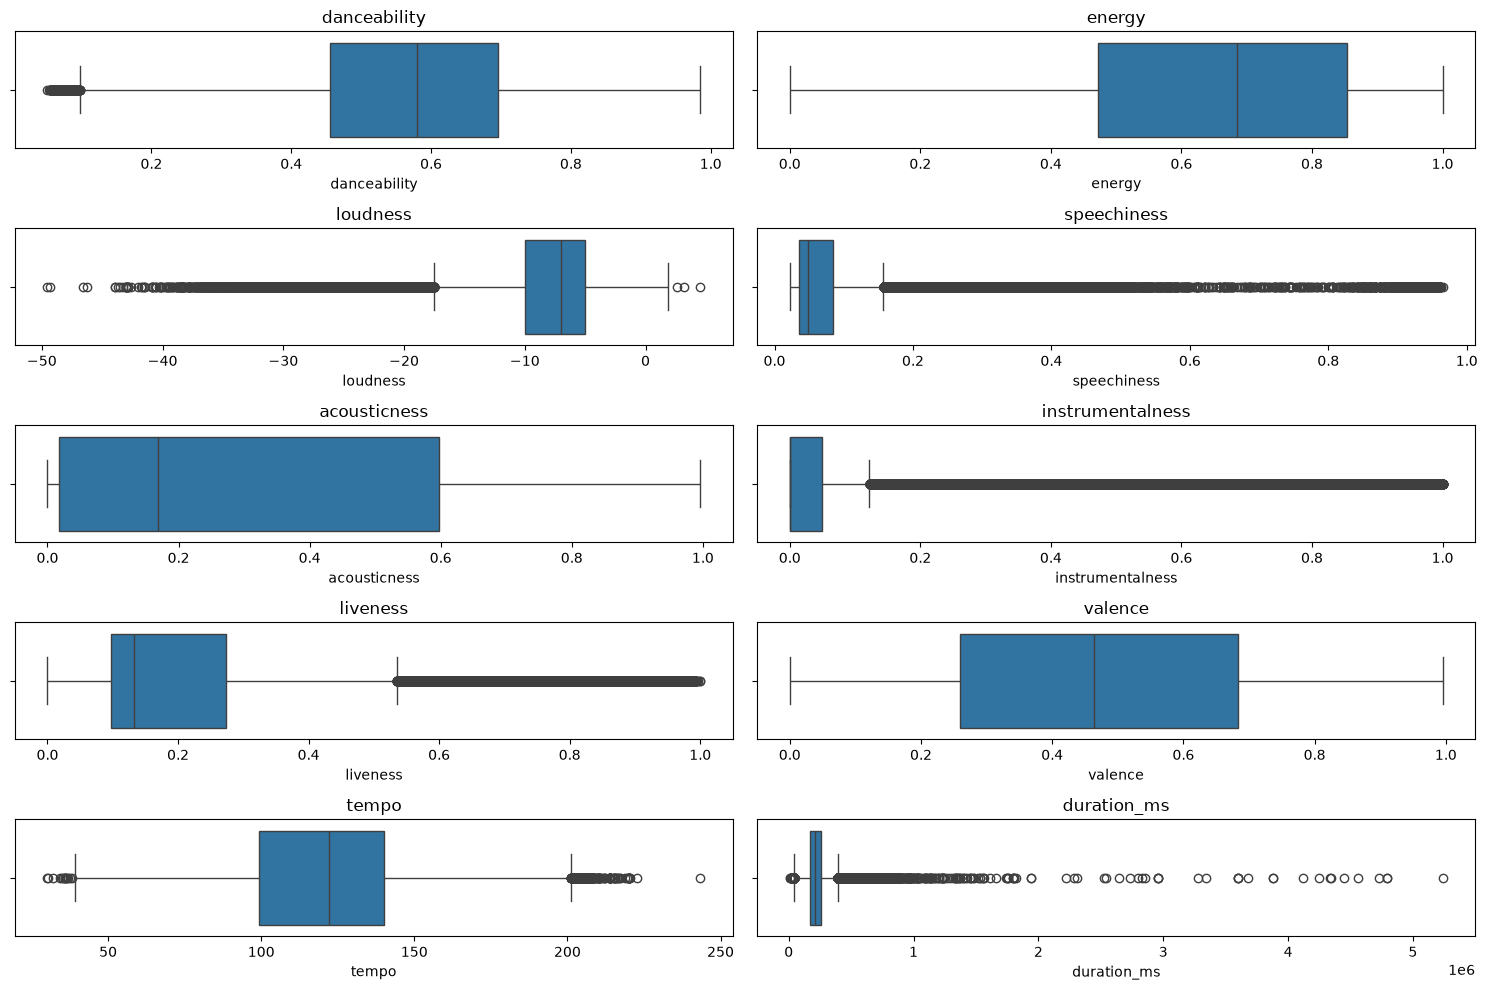

In [58]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_features, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(x=data[column])
    plt.title(column)

plt.tight_layout()
plt.show()